# Eksploracja danych — Laboratorium 1
## Python do analizy danych: przypomnienie

**Cel zajęć:** odświeżyć Pythona i poznać podstawy narzędzi, których będziemy używać przez cały semestr: **NumPy**, **pandas** i **matplotlib**.

**Plan:**
1. Python w pigułce
2. NumPy
3. pandas — pierwsze kroki
4. Wykresy w matplotlib

**Zadania** mają dwa poziomy:
- 🟢 **podstawowe** — obowiązkowe,
- 🔵 **dla ambitnych** — dodatkowe.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, rozwiąż zadania w miejscach oznaczonych `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 12})

---
# 1. Python w pigułce

In [2]:
# Listy, indeksowanie i wycinanie (slicing)
temperatury = [12.5, 14.0, 9.8, 17.3, 15.1]

print(temperatury[0])     # pierwszy element
print(temperatury[-1])    # ostatni element
print(temperatury[1:3])   # elementy o indeksach 1 i 2
print(len(temperatury))

12.5
15.1
[14.0, 9.8]
5


In [3]:
# Pętla for, enumerate i zip
dni = ["pon", "wt", "śr", "czw", "pt"]

for i, t in enumerate(temperatury):
    print(f"[{i}] -> {t}")

for dzien, t in zip(dni, temperatury):
    print(f"{dzien}: {t:.1f} °C")   # :.1f — jedna cyfra po przecinku

[0] -> 12.5
[1] -> 14.0
[2] -> 9.8
[3] -> 17.3
[4] -> 15.1
pon: 12.5 °C
wt: 14.0 °C
śr: 9.8 °C
czw: 17.3 °C
pt: 15.1 °C


In [4]:
# Słownik: klucz -> wartość
miasto = {"nazwa": "Łódź", "wojewodztwo": "łódzkie", "ludnosc_2021": 670_642}

print(miasto["nazwa"])
for klucz, wartosc in miasto.items():
    print(klucz, "=", wartosc)

Łódź
nazwa = Łódź
wojewodztwo = łódzkie
ludnosc_2021 = 670642


In [5]:
# Funkcja z docstringiem
def potega(lista, p):
    """
    Podnosi każdy element listy do potęgi p.

    Parametry:
    - lista (list): lista liczb,
    - p (int | float): wykładnik.

    Zwraca:
    - list: nowa lista z elementami podniesionymi do potęgi p.
    """
    wynik = []
    for x in lista:
        wynik.append(x ** p)
    return wynik


print(potega([1, 2, 3, 4], 3))
help(potega)   # w Jupyterze/Colabie także: potega?

[1, 8, 27, 64]
Help on function potega in module __main__:

potega(lista, p)
    Podnosi każdy element listy do potęgi p.

    Parametry:
    - lista (list): lista liczb,
    - p (int | float): wykładnik.

    Zwraca:
    - list: nowa lista z elementami podniesionymi do potęgi p.



### List comprehension

Zwięzły sposób tworzenia list:
```python
[wyrażenie for element in kolekcja if warunek]
```

In [6]:
print([x ** 2 for x in range(6)])
print([x ** 2 for x in range(6) if x % 2 == 0])

[0, 1, 4, 9, 16, 25]
[0, 4, 16]


### 🟢 Zadanie 1: średnia i mediana

Lista `dlugosc_zycia` zawiera oczekiwaną długość życia (w latach) w 14 krajach.

1. Napisz funkcję `srednia(liczby)`, która zwraca średnią arytmetyczną — **bez** używania `sum()` i NumPy (użyj pętli).
2. Napisz funkcję `mediana(liczby)`, która zwraca medianę. Pamiętaj o przypadku parzystej i nieparzystej liczby elementów. Wskazówka: `sorted()`.
3. Porównaj wyniki z `np.mean()` i `np.median()`.

🔵 **Dla ambitnych:** niech obie funkcje zgłaszają czytelny błąd (`raise ValueError(...)`), gdy lista jest pusta.

In [5]:
dlugosc_zycia = [81.8, 81.0, 82.6, 83.0, 81.8, 84.3, 82.8, 81.9, 82.2, 82.0, 82.7, 79.8, 83.3, 82.0]

In [8]:
def srednia(nums):
    if len(nums) == 0:
        raise ValueError("Podana lista jest pusta!")
    
    sum_of_elements = 0.0
    for element in nums:
        sum_of_elements += element
        
    return sum_of_elements / len(nums)


def mediana(nums):
    if len(nums) == 0:
        raise ValueError("Podana lista jest pusta!")
    
    sorted_nums = sorted(nums)
    size = len(sorted_nums)
    mid = size // 2

    if size % 2 != 0: # if odd number, take single in the middle
        return sorted_nums[mid]

    return (sorted_nums[mid - 1] + sorted_nums[mid]) / 2 # if even, take mean of 2 in the middle


# Porównanie wyników z biblioteką NumPy:
my_mean = srednia(dlugosc_zycia)
np_mean = np.mean(dlugosc_zycia)

my_median = mediana(dlugosc_zycia)
np_median = np.median(dlugosc_zycia)

print(f"Średnia:  {my_mean:.4f} (własna) vs {np_mean:.4f} (NumPy)")
print(f"Mediana:  {my_median:.4f} (własna) vs {np_median:.4f} (NumPy)")


Średnia:  82.2286 (własna) vs 82.2286 (NumPy)
Mediana:  82.1000 (własna) vs 82.1000 (NumPy)


### 🟢 Zadanie 2: zliczanie

Napisz funkcję `zlicz(lista)`, która zwraca słownik: element → liczba jego wystąpień.

Przykład: `zlicz(["a", "b", "a", "c", "a"])` → `{"a": 3, "b": 1, "c": 1}`

Sprawdź ją na liście `oceny`. Która ocena występuje najczęściej?

In [9]:
oceny = [4, 3, 5, 4, 4, 2, 3, 5, 4, 3, 4, 5, 3, 4]

def zlicz(items):
    counts = {}
    for item in items:
        counts[item] = counts.get(item, 0) + 1
    return counts

grade_counts = zlicz(oceny)
print("Grade distribution:", grade_counts)

# Most frequent grade
most_frequent_grade = max(grade_counts, key=grade_counts.get)
print(f"Most frequent grade: {most_frequent_grade} (appeared {grade_counts[most_frequent_grade]} times)")


Grade distribution: {4: 6, 3: 4, 5: 3, 2: 1}
Most frequent grade: 4 (appeared 6 times)


### 🟢 Zadanie 3: list comprehension

Dla listy `temperatury` (w °C) z początku notatnika:

1. Utwórz listę temperatur w stopniach Fahrenheita: $F = \frac{9}{5}C + 32$.
2. Utwórz listę tylko tych temperatur (w °C), które są wyższe niż 13 °C.
3. Utwórz listę napisów w postaci `"pon: 12.5 °C"` (wskazówka: `zip`).

Każdy punkt rozwiąż **jedną** linią.

In [ ]:
# 1. Convert temperatures to Fahrenheit
temps_fahrenheit = [(9 / 5) * temp + 32 for temp in temperatury]

# 2. Filter temperatures above 13 °C
temps_above_13 = [temp for temp in temperatury if temp > 13]

# 3. Combine day abbreviations and temperatures into formatted strings
formatted_daily_temps = [f"{day}: {temp} °C" for day, temp in zip(dni, temperatury)]

print("Fahrenheit:", temps_fahrenheit)
print("Above 13 °C:", temps_above_13)
print("Daily labels:", formatted_daily_temps)


---
# 2. NumPy

**NumPy** to podstawa obliczeń numerycznych w Pythonie — na nim zbudowane są pandas, scikit-learn i wiele innych bibliotek. Kluczowa idea: **wektoryzacja**, czyli operacje na całych tablicach naraz, bez pisania pętli.

In [11]:
a = np.array([1, 2, 3, 4, 5])
print(a, a.dtype, a.shape)

print(np.arange(0, 10, 2))       # od 0 do 10 (bez 10) co 2
print(np.linspace(0, 1, 5))      # 5 równo rozłożonych punktów od 0 do 1 (z 1)
print(np.zeros(3), np.ones(3))

[1 2 3 4 5] int64 (5,)
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[0. 0. 0.] [1. 1. 1.]


### Lista ≠ tablica

Te same operatory działają inaczej na listach i na tablicach NumPy:

In [12]:
lista = [1, 2, 3]
lista2 = [1,2,3,4]
tablica = np.array([1, 2, 3])
tablica2 = np.array([1, 2, 3,4])


print("lista * 2   =", lista * 2)      # powtórzenie listy!
print("tablica * 2 =", tablica * 2)    # mnożenie każdego elementu
print("lista + lista     =", lista + lista2)        # sklejenie list
print("tablica + tablica =", tablica + tablica)    # dodawanie element po elemencie. tablica + tablica2 wywoła błąd bo różny rozmiar tablic.

lista * 2   = [1, 2, 3, 1, 2, 3]
tablica * 2 = [2 4 6]
lista + lista     = [1, 2, 3, 1, 2, 3, 4]
tablica + tablica = [2 4 6]


In [13]:
# Maski logiczne i agregacje
pomiary = np.array([7, 5, 4, 8, 4, 2, 9, 4, 100])

print("maska > 5:", pomiary > 5)
print("wartości > 5:", pomiary[pomiary > 5])
print("ile > 5:", (pomiary > 5).sum())

print("min, max:", pomiary.min(), pomiary.max())
print("średnia:", pomiary.mean())
print("mediana:", np.median(pomiary))
print("odchylenie standardowe:", pomiary.std())

maska > 5: [ True False False  True False False  True False  True]
wartości > 5: [  7   8   9 100]
ile > 5: 4
min, max: 2 100
średnia: 15.88888888888889
mediana: 5.0
odchylenie standardowe: 29.812169194789657


### Liczby losowe

Używamy **generatora** `np.random.default_rng()`. Ustalone ziarno (`seed`) daje powtarzalne wyniki.

In [14]:
rng = np.random.default_rng(seed=42)

print(rng.integers(1, 7, size=10))        # 10 rzutów kostką: liczby całkowite z [1, 7)
print(rng.uniform(0, 1, size=3))          # 3 liczby z rozkładu jednostajnego na [0, 1)
print(rng.normal(loc=0, scale=1, size=3)) # 3 liczby z rozkładu normalnego N(0, 1)

[1 5 4 3 3 6 1 5 2 1]
[0.97562235 0.7611397  0.78606431]
[-0.01680116 -0.85304393  0.87939797]


### 🟢 Zadanie 4: dlaczego NumPy?

Zsumuj liczby od 1 do 1 000 000 na **cztery sposoby** i zmierz czas każdego z nich magiczną komendą `%timeit`:

1. pętla `for`,
2. `sum()` na liście zbudowanej przez list comprehension,
3. `sum(range(...))`,
4. NumPy: `np.arange(...).sum()`.

Sprawdź, czy wszystkie dają ten sam wynik. Który sposób jest najszybszy i **dlaczego**? Odpowiedz w komórce tekstowej.

In [ ]:
N = 1_000_000

# 1. Standard for-loop accumulation
def sum_with_loop(n):
    total = 0
    for val in range(1, n + 1):
        total += val
    return total

# 2. Built-in sum() on a list from comprehension
def sum_with_comprehension(n):
    return sum([val for val in range(1, n + 1)])

# 3. Built-in sum() directly on range generator
def sum_with_range(n):
    return sum(range(1, n + 1))

# 4. NumPy vectorized sum on ndarray
def sum_with_numpy(n):
    return np.arange(1, n + 1, dtype=np.int64).sum()

# Verify that all 4 implementations give identical results:
results = [sum_with_loop(N), sum_with_comprehension(N), sum_with_range(N), int(sum_with_numpy(N))]
assert len(set(results)) == 1, "Results differ!"
print(f"All methods produced the exact same sum: {results[0]:,}")

# Benchmark execution times using %timeit:
print("\n--- Timing: for-loop ---")
%timeit sum_with_loop(N)

print("\n--- Timing: list comprehension + sum ---")
%timeit sum_with_comprehension(N)

print("\n--- Timing: range + sum ---")
%timeit sum_with_range(N)

print("\n--- Timing: NumPy arange.sum ---")
%timeit sum_with_numpy(N)


All methods produced the exact same sum: 500,000,500,000

--- Timing: for-loop ---
14.5 ms ± 366 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)

--- Timing: list comprehension + sum ---


*Twoja odpowiedź:*
Wyniki wszystkich metod są identyczne.

Najszybszy jest **NumPy**, bo wykonuje obliczenia w skompilowanym kodzie C bez interpretera Pythona.

Najwolniejsze jest **list comprehension**, ponieważ musi najpierw zaalokować w pamięci całą listę miliona liczb przed ich zsumowaniem.


### 🟢 Zadanie 5: operacje na tablicach

Dana jest tablica `x` z pomiarami temperatury (°C).

1. Policz średnią, odchylenie standardowe, minimum i maksimum.
2. Wybierz pomiary wyższe od średniej. Ile ich jest?
3. **Normalizacja min–max:** przeskaluj `x` do przedziału $[0, 1]$: $\;x' = \dfrac{x - x_{\min}}{x_{\max} - x_{\min}}$
4. **Standaryzacja:** $\;z = \dfrac{x - \bar{x}}{s}$. Sprawdź, że wynik ma średnią ≈ 0 i odchylenie standardowe ≈ 1.

Wszystko bez pętli!

In [ ]:
temps = np.array([12.5, 14.0, 9.8, 17.3, 15.1, 11.2, 18.6, 16.0, 13.4, 10.9])

# 1. Summary statistics
mean_val = temps.mean()
std_val = temps.std()
min_val = temps.min()
max_val = temps.max()
print(f"1. Summary Stats -> Mean: {mean_val:.2f}, Std: {std_val:.2f}, Min: {min_val:.1f}, Max: {max_val:.1f}")

# 2. Filter measurements above mean and count them
above_mean = temps[temps > mean_val]
print(f"2. Readings > mean: {above_mean} (Count: {above_mean.size})")

# 3. Min-Max normalization into [0, 1]
norm_temps = (temps - min_val) / (max_val - min_val)
print(f"3. Min-Max normalized:\n{norm_temps.round(4)}")

# 4. Standardization (Z-score: mean ≈ 0, std ≈ 1)
standardized = (temps - mean_val) / std_val
print(f"4. Standardized (z-scores):\n{standardized.round(4)}")
print(f"   Validation -> Mean: {standardized.mean():.4e} (~0), Std: {standardized.std():.4f} (~1)")


### 🟢 Zadanie 6: rzuty kostką

1. Zasymuluj 10 000 rzutów kostką do gry (`rng.integers`).
2. Policz, ile razy wypadła każda liczba oczek (wskazówka: `np.unique(..., return_counts=True)`) i jaki to odsetek wszystkich rzutów.
3. Policz średnią liczbę oczek. Jakiej wartości się spodziewasz?

🔵 **Dla ambitnych:** zasymuluj 10 000 rzutów **dwiema** kostkami i policz rozkład sumy oczek. Która suma wypada najczęściej i dlaczego?

In [ ]:
generator = np.random.default_rng(seed=42)
num_rolls = 10_000

# 1. Simulate 10,000 rolls with a 6-sided die
single_rolls = generator.integers(1, 7, size=num_rolls)

# 2. Calculate counts and percentages for each face
faces, counts = np.unique(single_rolls, return_counts=True)
percentages = counts / num_rolls

print("--- Single Die Roll Statistics ---")
for face, count, pct in zip(faces, counts, percentages):
    print(f"Face {face}: {count:5d} occurrences ({pct:6.2%})")

# 3. Mean score (expected value: 3.5)
print(f"\nAverage roll: {single_rolls.mean():.4f} (Theoretical: 3.5)")

# 🔵 For the ambitious: Two dice simulation
die_a = generator.integers(1, 7, size=num_rolls)
die_b = generator.integers(1, 7, size=num_rolls)
dice_sums = die_a + die_b

sum_values, sum_counts = np.unique(dice_sums, return_counts=True)
most_common_sum = sum_values[np.argmax(sum_counts)]

print("\n--- Two Dice Sum Distribution ---")
for s_val, s_cnt in zip(sum_values, sum_counts):
    print(f"Sum {s_val:2d}: {s_cnt:5d} times ({s_cnt / num_rolls:6.2%})")

print(f"\nNajczęstsza suma: {most_common_sum} (wypada najczęściej, bo ma najwięcej kombinacji: 6 z 36).")


---
# 3. pandas — pierwsze kroki

**pandas** służy do pracy z danymi tabelarycznymi. Podstawowe struktury:
- `Series` — jedna kolumna (wektor z etykietami),
- `DataFrame` — tabela, czyli zbiór kolumn o wspólnym indeksie.

### DataFrame ze słownika

In [18]:
dane = {
    "miasto": ["Warszawa", "Kraków", "Łódź", "Wrocław", "Poznań"],
    "ludnosc_2021": [1_860_281, 800_653, 670_642, 674_079, 546_859],
    "powierzchnia_km2": [517, 327, 293, 293, 262],
}
miasta = pd.DataFrame(dane)
miasta

,miasto,ludnosc_2021,powierzchnia_km2
0,Warszawa,1860281,517
1,Kraków,800653,327
2,Łódź,670642,293
3,Wrocław,674079,293
4,Poznań,546859,262


In [19]:
# Nowa kolumna obliczona z innych kolumn
miasta["gestosc"] = miasta["ludnosc_2021"] / miasta["powierzchnia_km2"]
miasta.sort_values("gestosc", ascending=False)

,miasto,ludnosc_2021,powierzchnia_km2,gestosc
0,Warszawa,1860281,517,3598.222437
1,Kraków,800653,327,2448.480122
3,Wrocław,674079,293,2300.610922
2,Łódź,670642,293,2288.880546
4,Poznań,546859,262,2087.248092


In [20]:
# Zapis do pliku CSV i ponowne wczytanie
miasta.to_csv("miasta.csv", index=False)
pd.read_csv("miasta.csv")

,miasto,ludnosc_2021,powierzchnia_km2,gestosc
0,Warszawa,1860281,517,3598.222437
1,Kraków,800653,327,2448.480122
2,Łódź,670642,293,2288.880546
3,Wrocław,674079,293,2300.610922
4,Poznań,546859,262,2087.248092


### Prawdziwy zbiór danych: `tips`

Zbiór `tips` zawiera 244 rachunki z restauracji, zapisane przez kelnera w ciągu kilku tygodni.

| kolumna | znaczenie |
|---|---|
| `total_bill` | kwota rachunku (USD) |
| `tip` | napiwek (USD) |
| `sex` | płeć płacącego |
| `smoker` | czy przy stoliku palono |
| `day` | dzień tygodnia |
| `time` | pora: lunch / obiad |
| `size` | liczba osób przy stoliku |

In [21]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Pierwszy rzut oka na dane

In [22]:
print(df.shape)     # (liczba wierszy, liczba kolumn)
df.info()           # typy kolumn i liczba niepustych wartości

(244, 7)
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [23]:
df.describe()       # statystyki opisowe kolumn liczbowych

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


### Wybieranie kolumn i wierszy

In [24]:
df["tip"].head()                    # jedna kolumna -> Series

0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64

In [25]:
df[["total_bill", "tip"]].head()    # kilka kolumn -> DataFrame (podwójne nawiasy!)

,total_bill,tip
0,16.99,1.01
1,10.34,1.66
2,21.01,3.50
3,23.68,3.31
4,24.59,3.61


In [26]:
print(df["tip"].mean(), df["tip"].max())   # metody kolumny

2.99827868852459 10.0


### `loc` czy `iloc`?

- `iloc` — wybiera po **pozycji** (0, 1, 2, …),
- `loc` — wybiera po **etykiecie indeksu**.

Póki indeks to 0, 1, 2, …, oba dają to samo. Różnica wychodzi na jaw po posortowaniu:

In [27]:
posortowane = df.sort_values("tip", ascending=False)
posortowane.head(3)

,total_bill,tip,sex,smoker,day,time,size
170,50.81,10.00,Male,Yes,Sat,Dinner,3
212,48.33,9.00,Male,No,Sat,Dinner,4
23,39.42,7.58,Male,No,Sat,Dinner,4


In [28]:
print("iloc[0] — pierwszy wiersz po posortowaniu (najwyższy napiwek):")
print(posortowane.iloc[0], "\n")

print("loc[0] — wiersz o etykiecie 0 (pierwszy rachunek w danych):")
print(posortowane.loc[0])

iloc[0] — pierwszy wiersz po posortowaniu (najwyższy napiwek):
total_bill     50.81
tip             10.0
sex             Male
smoker           Yes
day              Sat
time          Dinner
size               3
Name: 170, dtype: object 

loc[0] — wiersz o etykiecie 0 (pierwszy rachunek w danych):
total_bill     16.99
tip             1.01
sex           Female
smoker            No
day              Sun
time          Dinner
size               2
Name: 0, dtype: object


### Filtrowanie

Warunki łączymy operatorami `&` (i), `|` (lub), `~` (nie) — każdy warunek **w nawiasach**.

In [29]:
duze_rachunki = df[df["total_bill"] > 40]
duze_rachunki

,total_bill,tip,sex,smoker,day,time,size
59,48.27,6.73,Male,No,Sat,Dinner,4
95,40.17,4.73,Male,Yes,Fri,Dinner,4
102,44.30,2.50,Female,Yes,Sat,Dinner,3
142,41.19,5.00,Male,No,Thur,Lunch,5
156,48.17,5.00,Male,No,Sun,Dinner,6
170,50.81,10.00,Male,Yes,Sat,Dinner,3
182,45.35,3.50,Male,Yes,Sun,Dinner,3
184,40.55,3.00,Male,Yes,Sun,Dinner,2
197,43.11,5.00,Female,Yes,Thur,Lunch,4
212,48.33,9.00,Male,No,Sat,Dinner,4


In [30]:
sobota_obiad = df[(df["day"] == "Sat") & (df["time"] == "Dinner")]
print(len(sobota_obiad), "rachunków w sobotę na obiedzie")

87 rachunków w sobotę na obiedzie


In [31]:
# Z .loc: wiersze spełniające warunek i wybrane kolumny
df.loc[df["size"] >= 5, ["total_bill", "tip", "size"]]

,total_bill,tip,size
125,29.80,4.20,6
141,34.30,6.70,6
142,41.19,5.00,5
143,27.05,5.00,6
155,29.85,5.14,5
156,48.17,5.00,6
185,20.69,5.00,5
187,30.46,2.00,5
216,28.15,3.00,5


In [32]:
df["day"].value_counts()    # ile razy występuje każda wartość

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

### 🟢 Zadanie 7: pytania do zbioru `tips`

Odpowiedz kodem:

1. Ile wierszy i kolumn ma zbiór? Jakie są nazwy kolumn?
2. Jaki jest średni, najmniejszy i największy rachunek?
3. Ile rachunków pochodzi z niedzieli (`"Sun"`)?
4. Pokaż 5 najwyższych rachunków.
5. Dodaj kolumnę `tip_pct` — napiwek jako procent rachunku. Jaki jest średni `tip_pct`?
6. Ile rachunków ma napiwek wyższy niż 20% rachunku?

🔵 **Dla ambitnych:**

7. Jaki jest średni `tip_pct` dla lunchu, a jaki dla obiadu? (Użyj filtrowania.)
8. Dodaj kolumnę `rachunek_na_osobe`. Przy którym stoliku rachunek na osobę był najwyższy?

In [44]:
# --- Część podstawowa 🟢 ---

# 1. Ile wierszy i kolumn ma zbiór? Jakie są nazwy kolumn?
print(f"1. Liczba wierszy: {df.shape[0]}, Liczba kolumn: {df.shape[1]}")
print(f"   Nazwy kolumn: {list(df.columns)}\n")

# 2. Jaki jest średni, najmniejszy i największy rachunek?
mean_bill = df["total_bill"].mean()
min_bill = df["total_bill"].min()
max_bill = df["total_bill"].max()
print(f"2. Średni rachunek: {mean_bill:.2f} USD")
print(f"   Najmniejszy rachunek: {min_bill:.2f} USD")
print(f"   Największy rachunek: {max_bill:.2f} USD\n")

# 3. Ile rachunków pochodzi z niedzieli ("Sun")?
sun_count = (df["day"] == "Sun").sum()
print(f"3. Liczba rachunków z niedzieli: {sun_count}\n")

# 4. Pokaż 5 najwyższych rachunków.
print("4. 5 najwyższych rachunków:")
top5_bills = df.sort_values("total_bill", ascending=False).head(5)
print(top5_bills, "\n")

# 5. Dodaj kolumnę `tip_pct` — napiwek jako procent rachunku. Jaki jest średni `tip_pct`?
df["tip_pct"] = (df["tip"] / df["total_bill"]) * 100
mean_tip_pct = df["tip_pct"].mean()
print(f"5. Średni tip_pct: {mean_tip_pct:.2f}%\n")

# 6. Ile rachunków ma napiwek wyższy niż 20% rachunku?
tips_over_20 = (df["tip_pct"] > 20).sum()
print(f"6. Liczba rachunków z napiwkiem > 20%: {tips_over_20}\n")


# --- Część dla ambitnych 🔵 ---

# 7. Jaki jest średni `tip_pct` dla lunchu, a jaki dla obiadu? (Użyj filtrowania.)
mean_tip_lunch = df[df["time"] == "Lunch"]["tip_pct"].mean()
mean_tip_dinner = df[df["time"] == "Dinner"]["tip_pct"].mean()
print(f"7. Średni tip_pct dla Lunch: {mean_tip_lunch:.2f}%")
print(f"   Średni tip_pct dla Dinner: {mean_tip_dinner:.2f}%\n")

# 8. Dodaj kolumnę `rachunek_na_osobe`. Przy którym stoliku rachunek na osobę był najwyższy?
df["rachunek_na_osobe"] = df["total_bill"] / df["size"]
max_per_person_idx = df["rachunek_na_osobe"].idxmax()
highest_per_person_row = df.loc[max_per_person_idx]

print(f"8. Najwyższy rachunek na osobę (indeks wiersza/stolika: {max_per_person_idx}):")
print(highest_per_person_row)

1. Liczba wierszy: 244, Liczba kolumn: 7
   Nazwy kolumn: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']

2. Średni rachunek: 19.79 USD
   Najmniejszy rachunek: 3.07 USD
   Największy rachunek: 50.81 USD

3. Liczba rachunków z niedzieli: 76

4. 5 najwyższych rachunków:
     total_bill    tip   sex smoker  day    time  size
170       50.81  10.00  Male    Yes  Sat  Dinner     3
212       48.33   9.00  Male     No  Sat  Dinner     4
59        48.27   6.73  Male     No  Sat  Dinner     4
156       48.17   5.00  Male     No  Sun  Dinner     6
182       45.35   3.50  Male    Yes  Sun  Dinner     3 

5. Średni tip_pct: 16.08%

6. Liczba rachunków z napiwkiem > 20%: 39

7. Średni tip_pct dla Lunch: 16.41%
   Średni tip_pct dla Dinner: 15.95%

8. Najwyższy rachunek na osobę (indeks wiersza/stolika: 184):
total_bill              40.55
tip                       3.0
sex                      Male
smoker                    Yes
day                       Sun
time                   Dinn

### 🟢 Zadanie 8: ludność Warszawy i Łodzi

| Rok | Warszawa | Łódź |
|---|---|---|
| 2002 | 1 672 000 | 789 318 |
| 2011 | 1 700 612 | 728 892 |
| 2015 | 1 740 000 | brak danych |
| 2021 | 1 860 281 | 670 642 |

1. Przekształć tabelę w słownik i utwórz z niego DataFrame. Brak danych zapisz jako `np.nan`.
2. Zapisz DataFrame do pliku `ludnosc.csv` i wczytaj go ponownie.
3. Sprawdź typy kolumn (`dtypes`) i liczbę braków (`isna().sum()`).
4. Policz zmianę procentową liczby ludności obu miast między 2011 a 2021 r.

🔵 **Dla ambitnych:** co się stanie z typem kolumny `Łódź`, jeśli zamiast `np.nan` wpiszesz tekst `"brak danych"`? Jak to naprawić? (Wskazówka: `pd.to_numeric(..., errors="coerce")`.)

In [34]:
# TODO

---
# 4. Wykresy w matplotlib

Używamy stylu obiektowego:
```python
fig, ax = plt.subplots()   # fig — cały rysunek, ax — jeden układ współrzędnych
ax.plot(...)
ax.set_xlabel(...)
```

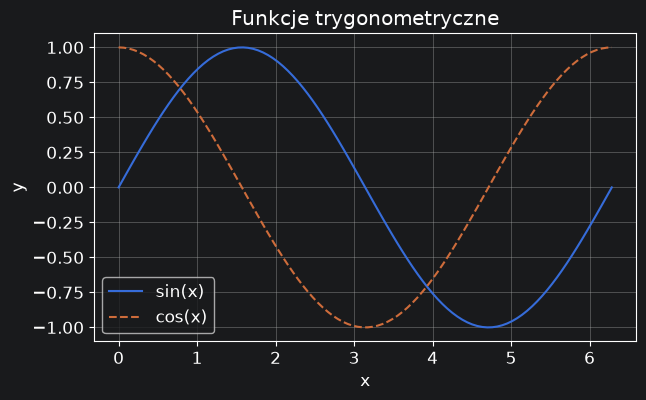

In [35]:
# Wykres liniowy
x = np.linspace(0, 2 * np.pi, 100)

fig, ax = plt.subplots()
ax.plot(x, np.sin(x), label="sin(x)")
ax.plot(x, np.cos(x), "--", label="cos(x)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Funkcje trygonometryczne")
ax.grid(True)
ax.legend();

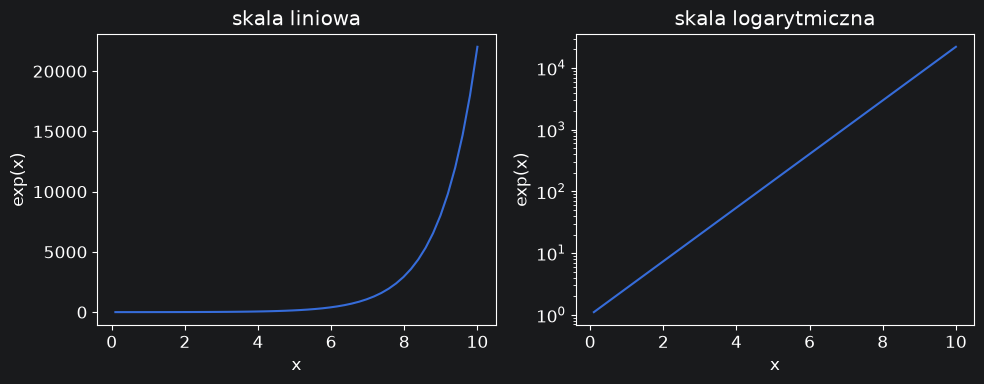

In [36]:
# Kilka paneli obok siebie; skala logarytmiczna
x = np.linspace(0.1, 10, 50)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(x, np.exp(x))
axs[0].set_title("skala liniowa")
axs[1].plot(x, np.exp(x))
axs[1].set_yscale("log")
axs[1].set_title("skala logarytmiczna")
for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("exp(x)")
fig.tight_layout()

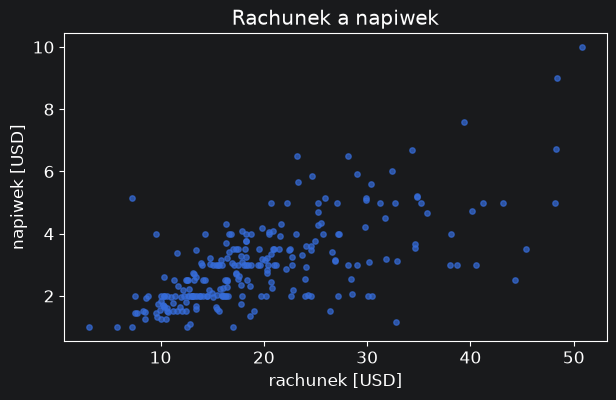

In [37]:
# Wykres punktowy
fig, ax = plt.subplots()
ax.scatter(df["total_bill"], df["tip"], s=15, alpha=0.7)
ax.set_xlabel("rachunek [USD]")
ax.set_ylabel("napiwek [USD]")
ax.set_title("Rachunek a napiwek");

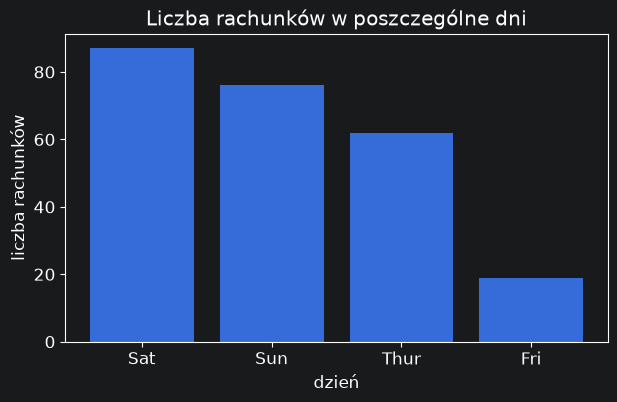

In [38]:
# Wykres słupkowy
liczba = df["day"].value_counts()

fig, ax = plt.subplots()
ax.bar(liczba.index, liczba.values)
ax.set_xlabel("dzień")
ax.set_ylabel("liczba rachunków")
ax.set_title("Liczba rachunków w poszczególne dni");

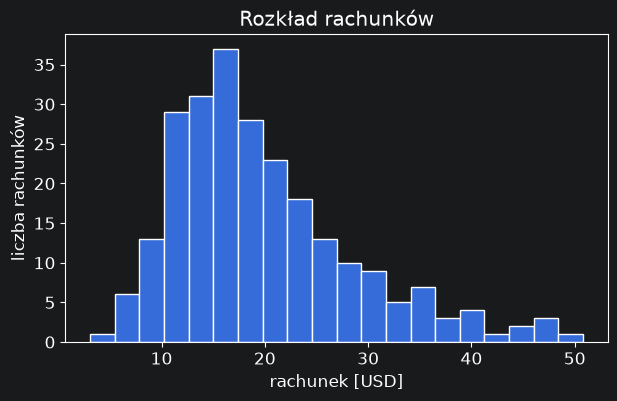

In [39]:
# Histogram — rozkład jednej zmiennej liczbowej
fig, ax = plt.subplots()
ax.hist(df["total_bill"], bins=20, edgecolor="white")
ax.set_xlabel("rachunek [USD]")
ax.set_ylabel("liczba rachunków")
ax.set_title("Rozkład rachunków");

### 🟢 Zadanie 9: lunch czy obiad?

Porównaj rozkład rachunków (`total_bill`) na lunchu i na obiedzie.

1. Narysuj dwa histogramy obok siebie (rysunek 10 × 4): lewy dla lunchu (`"Lunch"`), prawy dla obiadu (`"Dinner"`).
2. Oba histogramy muszą mieć **te same przedziały** (`bins=np.arange(0, 60, 5)`) i **wspólne osie** (`plt.subplots(..., sharex=True, sharey=True)`) — inaczej porównanie będzie mylące.
3. Na każdym panelu zaznacz średni rachunek pionową linią przerywaną (`ax.axvline(...)`) i podpisz ją w legendzie.
4. Dodaj tytuły i opisy osi z jednostkami.
5. W komórce tekstowej odpowiedz: kiedy rachunki są wyższe? Ile jest rachunków w każdej grupie?

🔵 **Dla ambitnych:** narysuj oba rozkłady na **jednym** wykresie (półprzezroczyste, `alpha=0.5`). Porównaj wersję z liczebnościami i z `density=True`. Dlaczego przy grupach różnej wielkości lepiej użyć `density=True`?

In [40]:
# TODO

*Twoja odpowiedź:* …

In [41]:
# 🔵 TODO

### 🟢 Zadanie 10: wykresy dla `tips` i ludności

1. Narysuj histogram napiwków (`tip`). Wypróbuj `bins` = 5, 20 i 50 — trzy panele obok siebie. Która liczba przedziałów najlepiej pokazuje kształt rozkładu?
2. Narysuj wykres liniowy liczby ludności Warszawy i Łodzi z zadania 8 (oba miasta na jednym wykresie, z legendą i znacznikami `marker="o"`).
3. Każdy wykres musi mieć tytuł i opisy osi z jednostkami.

In [42]:
# TODO

### 🔵 Zadanie 11 (dla ambitnych): rozkład normalny

1. Napisz funkcję gęstości rozkładu normalnego:
$$ f(x; \mu, \sigma) = \frac{1}{\sigma\sqrt{2\pi}} \exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right) $$
2. Dla trzech par $(\mu, \sigma)$: (0, 1), (0, 2), (2, 1) wygeneruj po 10 000 liczb (`rng.normal`) i narysuj ich histogram (`density=True`) razem z krzywą gęstości policzoną ze wzoru.
3. Trzy wykresy jeden pod drugim, każdy z tytułem zawierającym $\mu$ i $\sigma$, opisami osi i legendą.

In [43]:
# TODO

---
# Podsumowanie

Po tych zajęciach potrafisz:
- [ ] posługiwać się listami, słownikami, pętlami, funkcjami i list comprehension,
- [ ] tworzyć tablice NumPy, liczyć na nich bez pętli i losować liczby,
- [ ] wczytać dane do pandas, obejrzeć je (`head`, `info`, `describe`) i wybierać wiersze oraz kolumny,
- [ ] tworzyć nowe kolumny i zapisywać dane do pliku CSV,
- [ ] narysować wykres liniowy, punktowy, słupkowy i histogram — z opisami osi.

**Do oddania:** ten notatnik z rozwiązanymi zadaniami 🟢 w Twoim repozytorium na GitHubie.